# FRECKLL Tutorial — Emilie version

This notebook is a walkthrough of [FRECKLL](https://ahmed-f-alrefaie.github.io/freckll/)
(**F**ull and **R**educed **E**xoplanet **C**hemical **K**inetics Disti**LL**ed), a Python
chemical-kinetics solver for exoplanet atmospheres. 

## What FRECKLL actually solves

FRECKLL integrates the continuity equation for each chemical species $i$ as a function of
height $z$ in the atmosphere:

$$
\frac{\partial n_i}{\partial t} = P_i - L_i - \frac{\partial \phi_i}{\partial z}
$$

where $n_i$ is the number density, $P_i$/$L_i$ are chemical production/loss rates, and
$\phi_i$ is the vertical transport flux (molecular diffusion + eddy/$K_{zz}$ mixing). What
sets FRECKLL apart numerically is its use of *distillation* (K-sum) arithmetic to avoid
catastrophic cancellation when summing production/loss terms that differ by many orders of
magnitude — this keeps the Jacobian smooth enough for stiff ODE solvers to converge.

## Prerequisites

```bash
pip install "freckll[recommended]"   # freckll + ACE equilibrium chemistry + matplotlib
```

- The `[ace]` extra (`acepython`) is required for the equilibrium-chemistry starting point
  used below. Without it, `freckll.ace` will fail to import.
- All reference data (Venot 2020 reaction networks, NASA thermochemical polynomials, stellar
  spectra) ships **inside** the `freckll` package via `importlib.resources` — there is no
  network download involved, so any "first call is slower" effect you see in the timers
  below is disk I/O + parsing, not internet latency.
- This notebook expects to be run from the `examples/` directory of the `freckll` repo, so
  that `inputs/tpprofile.csv` and `inputs/kzz.csv` resolve correctly.

## Silencing some warnings

Solving thousands of ODE steps triggers three warnings on every call:

- `MatrixRankWarning: Matrix is exactly singular` (`freckll/solver/rosenbrock.py`) — the
  Rosenbrock step's linear solve occasionally hits a singular Jacobian on a step that gets
  rejected and retried with a smaller step size; it's not fatal on its own.
- `UserWarning: 'where' used without 'out', ...` (`freckll/reactions/common.py`) — an
  `np.divide(..., where=...)` call there doesn't pass `out=`, so numpy warns about
  uninitialized memory in the masked-out entries. Harmless since freckll never reads those
  masked entries.
- `RuntimeWarning: divide by zero encountered in scalar divide` (`freckll/solver/solver.py`,
  in `convergence_test`) — `dydt = dy / (t[-1] - t[-2])` divides by zero whenever two
  consecutive saved time points are identical (e.g. a rejected/retried step). The result is
  `inf`/`nan`, which then correctly fails the `dydt < dfdt_criteria` convergence check rather
  than silently reporting false convergence — so this is a noisy edge case, not a wrong
  answer.

All three are filtered below so they don't flood the output of the long solves later in this
notebook. **Caveat**: if a solve ever comes back with `result["success"] == False` alongside
a flood of these warnings, that's the one case where it isn't just noise — it means the
solver genuinely struggled (usually at an extreme corner of a parameter range) and is worth
investigating rather than ignoring.

In [1]:
%%time
import warnings

from scipy.sparse.linalg import MatrixRankWarning

warnings.filterwarnings("ignore", category=MatrixRankWarning)
warnings.filterwarnings("ignore",message=r"'where' used without 'out'",category=UserWarning,)
warnings.filterwarnings("ignore",message=r"divide by zero encountered in scalar divide",category=RuntimeWarning,)

CPU times: user 374 ms, sys: 162 ms, total: 536 ms
Wall time: 2 s


## Loading atmospheric data

FRECKLL is built around `astropy.units.Quantity` objects rather than bare floats/arrays.
Every physical quantity (temperature, pressure, Kzz, planet radius, ...) carries its unit,
so the library never has to guess whether you handed it bars or Pascals, cm or Rjup. This
also means unit conversions (e.g. `result["kzz"].to(u.km**2 / u.s)`) are free correctness
checks — astropy will raise if you try to convert between incompatible units.

The simplest way to build a profile is directly with numpy + `<<` (astropy's "attach a
unit" operator):


In [2]:
%%time
import numpy as np
from astropy import units as u

# Isothermal temperature-pressure profile with 100 points
# `<<` attaches units without any unit conversion
temperature = np.linspace(2000, 10000, 100) << u.K
pressure = np.logspace(2, -5) << u.bar


CPU times: user 159 ms, sys: 69.4 ms, total: 229 ms
Wall time: 634 ms


You can also load real profile from a csv file.
Column 0 is pressure (mbar), column 1 is temperature (K). We tell the loader which column
is which and which units they're in.


In [3]:
%%time
from freckll.io.loader import tp_profile_loader

pressure, temperature = tp_profile_loader(
    filename="inputs/tpprofile.csv",
    temperature_column=1,
    temperature_unit=u.K,
    pressure_column=0,
    pressure_unit=u.mbar,
    comments="#",
)

print("Profile shape:", pressure.shape)


Profile shape: (130,)
CPU times: user 144 ms, sys: 55.4 ms, total: 199 ms
Wall time: 562 ms


We can also laod the kzz profile for the eddy diffusion coefficient:


In [4]:
%%time
from freckll.io.loader import kzz_profile_loader

# Careful! Kzz can be measured/tabulated on a different pressure grid than the TP profile (see below).
_pressure, kzz = kzz_profile_loader(
    filename="inputs/kzz.csv",
    kzz_column=1,
    pressure_column=0,
    kzz_unit=u.cm**2 / u.s,
    pressure_unit=u.mbar,
    comments="#",
)
print("Kzz shape:", kzz.shape)


Kzz shape: (28369,)
CPU times: user 17.5 ms, sys: 4.84 ms, total: 22.4 ms
Wall time: 21.4 ms


`kzz.shape` is deliberately different from `pressure.shape` in this example. Before we can hand both profiles to the solver they need to live on the
*same* pressure grid, so we interpolate Kzz onto the TP profile's grid 


In [5]:
%%time
from freckll.utils import interpolate_pressure

kzz = interpolate_pressure(_pressure, kzz, pressure)
print("Kzz shape after interpolation:", kzz.shape, "(now matches pressure:", pressure.shape, ")")


Kzz shape after interpolation: (130,) (now matches pressure: (130,) )
CPU times: user 402 ms, sys: 112 ms, total: 515 ms
Wall time: 1.48 s


Sanity-check both profiles visually


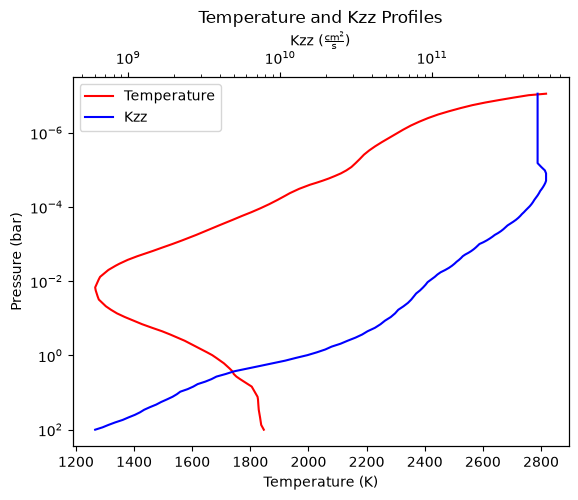

CPU times: user 714 ms, sys: 136 ms, total: 850 ms
Wall time: 1.97 s


In [6]:
%%time
import matplotlib.pyplot as plt

from freckll.plot import plot_tp_and_kzz

fig, ax = plt.subplots()
plot_tp_and_kzz(pressure, temperature, kzz, ax)
plt.show()


## Loading the chemical network

The "network" is the set of species + reactions (rates, stoichiometry, falloff behavior,
...) that FRECKLL integrates. FRECKLL ships two built-in Venot-2020 networks:

| Loader argument                     | Species        | Photolysis? | Use when...                              |
|--------------------------------------|----------------|-------------|-------------------------------------------|
| `"venot-methanol-2020-reduced"`      | smaller subset | No          | You don't need UV photochemistry — faster |
| `"venot-methanol-2020"`              | full set       | Yes (needs a separate photo-network, see §7) | You need photochemistry |

(There's also `"veillet-2024"` / `"veillet-2024-photo"` for the newer Veillet network — same
loader, different string)

We'll start with the reduced network since it's cheaper and doesn't need photochemistry
set up:


In [7]:
%%time
from freckll.io.loader import default_network_loader

network = default_network_loader("venot-methanol-2020-reduced")


CPU times: user 39.3 ms, sys: 3.79 ms, total: 43.1 ms
Wall time: 138 ms


Inspect the species list:


In [8]:
%%time
print(f"Network has {len(network.species)} species")
print(network.species)


Network has 44 species
[C2H3O2 (CH3OCO), HO2 (OOH), C2H3O (CH2CHO), C2H3O (CH3CO), CNO (NCO), CH3O (CH3O), O2 (O2), CHO2 (CO2H), CHNO (HOCN), C2H5 (C2H5), CH3O (CH2OH), C2H6 (C2H6), C2H3 (C2H3), C2H2O (CH2CO), HN2 (NNH), CH2N (H2CN), CH4O (CH3OH), CN (CN), CH2 (1CH2), CHNO (HNCO), O (O3P), C2H4 (C2H4), CH2 (3CH2), CHO (HCO), C2H2 (C2H2), CH2O (H2CO), H2N (NH2), CO2 (CO2), HO (OH), CH3 (CH3), CHN (HCN), H3N (NH3), CH4 (CH4), N2 (N2), CO (CO), H2O (H2O), H (H), He (He), H2 (H2), H2N2 (N2H2), H3N2 (N2H3), CH2N (HCNH), CH2O2 (HOCHO), CH3O2 (HOCH2O)]
CPU times: user 55 μs, sys: 6 μs, total: 61 μs
Wall time: 57.9 μs


### Performance: precompiling reactions

A production retrieval or forward-model run calls `compute_reactions` **thousands** of times
as the ODE solver takes steps so its per-call cost matters a lot.
`network.compile_reactions(...)` pre-evaluates everything that only depends on
temperature/pressure (not VMR), so repeated `compute_reactions` calls at the *same* T/P
profile skip that work.


In [9]:
vmr = np.random.rand(len(network.species), len(pressure))
vmr = vmr / np.sum(vmr, axis=0, keepdims=True)

In [10]:
# Baseline: compute_reactions() re-derives T/P-dependent quantities every single call.
%timeit network.compute_reactions(vmr, temperature, pressure)


8.89 ms ± 115 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


Now compile the network once for this T/P profile, and re-time `compute_reactions`
— note we can drop the `temperature`/`pressure` arguments entirely once compiled, since
they're baked into the compiled reaction calls:


In [11]:
network.compile_reactions(temperature, pressure)

# Compare against the baseline above, this should be faster per call
%timeit network.compute_reactions(vmr)


6.64 ms ± 41.1 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


## Running from an equilibrium starting point

Starting from *random* VMR is an okay exercise, but a physically-motivated run
should start from a thermochemical-equilibrium state at the given elemental abundances, then
let disequilibrium kinetics relax it away from equilibrium. 


FRECKLL can use two solvers:

- **VODE** variable-order, variable-step BDF family solver (via `scipy`/classic `vode`).
- **Rosenbrock** a linearly-implicit Rosenbrock method (following the VULCAN paper,
  Tsai et al. 2017), often more robust for these particular stiff photochemical/kinetic
  systems.

We'll use Rosenbrock here.


In [12]:
%%time
from freckll.solver import Rosenbrock

rosen = Rosenbrock(network=network)


CPU times: user 14 μs, sys: 4 μs, total: 18 μs
Wall time: 18.8 μs


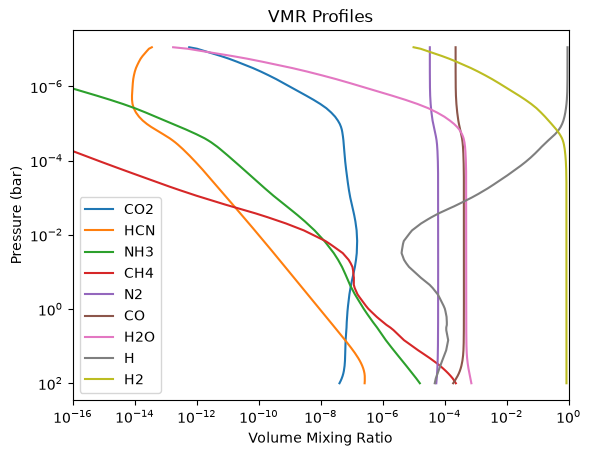

CPU times: user 73.6 ms, sys: 10.1 ms, total: 83.7 ms
Wall time: 130 ms


In [13]:
%%time
from freckll.ace import equil_chemistry_ace

# elements/abundances here are solar-ish log-abundances (H, He, C, N, O) returns a (n_species, n_layers) VMR array 
equil_vmr = equil_chemistry_ace(
    temperature=temperature,
    pressure=pressure,
    composition=network.species,
    elements=["H", "He", "C", "N", "O"],
    abundances=[12, 10.93, 8.39, 7.86, 8.73],
)

from freckll.plot import plot_vmr
fig, ax = plt.subplots()
plot_vmr(
    equil_vmr,
    pressure,
    network.species,
    ax=ax,
)
plt.show()


Before solving, tell the solver about the physical system: the TP/Kzz profiles and
the planet's bulk properties (radius/mass, which set the gravity and scale height used in
the diffusion terms):


In [14]:
%%time
rosen.set_system_parameters(
    temperature=temperature,
    pressure=pressure,
    kzz=kzz,
    planet_radius=1.37 * u.Rjup,
    planet_mass=0.87 << u.Mjup,
)


CPU times: user 3.17 ms, sys: 1.6 ms, total: 4.77 ms
Wall time: 3.5 ms


`solve()` takes an **initial** VMR and a time span to integrate over `t_span=[0, 1e16]`
seconds is "run until steady state or until this cap, whichever comes first" for a typical
hot-Jupiter-like case. 

In [15]:
%%time
result_equil = rosen.solve(
    vmr=equil_vmr,
    t_span=[0, 1e16],
    enable_diffusion=False,
    maxiter=1000,
)
print("Success:", result_equil["success"])


Success: True
CPU times: user 8.86 s, sys: 396 ms, total: 9.26 s
Wall time: 11 s


`result` is a `SolverResult` dict with (among others):

- `success` — did the integrator converge/terminate cleanly
- `times` — time points sampled during integration
- `vmr` — VMR at every saved time point, shape `(n_times, n_species, n_layers)`
- `initial_vmr` — the VMR we started from
- `temperature`, `pressure`, `density`, `kzz` — the atmospheric state (density derived from
  T/P via the ideal gas law)
- `planet`, `species` — bookkeeping for plotting/output

Plot the initial vs. final (steady-state) mixing ratios for the usual suspects
(H2O, CH4, CO2, ...) — dashed = initial, solid = converged:


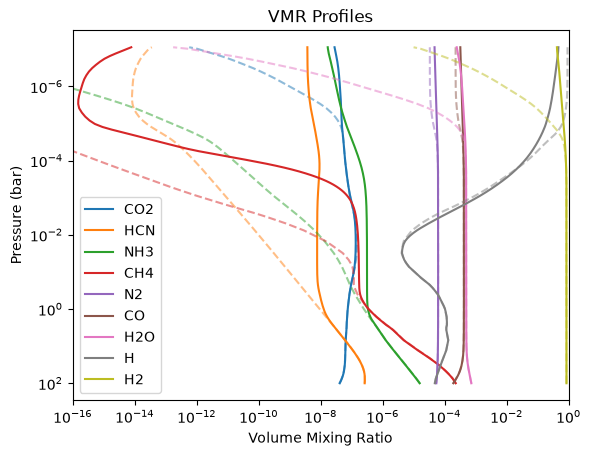

CPU times: user 70.8 ms, sys: 8.89 ms, total: 79.7 ms
Wall time: 78.6 ms


In [16]:
%%time
fig, ax = plt.subplots()
plot_vmr(
    result_equil["vmr"][-1],
    result_equil["pressure"],
    result_equil["species"],
    initial_vmr=result_equil["initial_vmr"],
    xlims=(1e-16, 1e0),
    ax=ax,
)
plt.show()


## Running with photochemistry

Photolysis requires the **full** Venot network, plus a separate `photochemistry` object and a stellar spectrum to
irradiate the atmosphere with. 


In [17]:
%%time
full_network = default_network_loader("venot-methanol-2020")
print(f"Full network has {len(full_network.species)} species (reduced had {len(network.species)})")


Full network has 108 species (reduced had 44)
CPU times: user 103 ms, sys: 3.46 ms, total: 106 ms
Wall time: 185 ms


In [18]:
%%time
from freckll.io.loader import default_photonetwork_loader, default_stellar_spectra_loader

# two positional args required?
photo_network = default_photonetwork_loader("venot-methanol-2020-photo", full_network.species)
stellar_spectra = default_stellar_spectra_loader("hd209458")


CPU times: user 62.9 ms, sys: 20.6 ms, total: 83.5 ms
Wall time: 498 ms


Sanity-check what we just loaded by plotting the stellar flux vs. wavelength


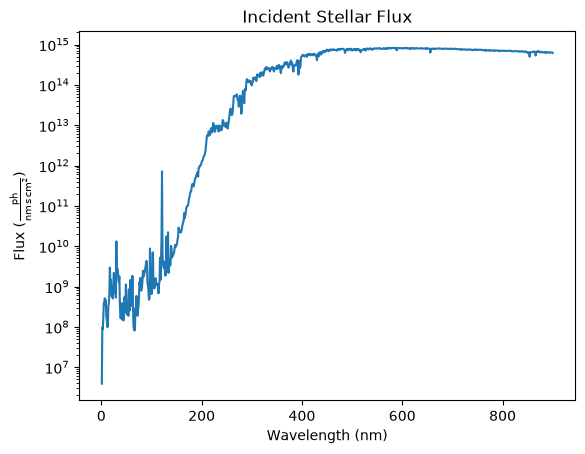

CPU times: user 118 ms, sys: 8.76 ms, total: 127 ms
Wall time: 131 ms


In [19]:
%%time
from freckll.plot import plot_stellar_flux

fig, ax = plt.subplots()
plot_stellar_flux(stellar_spectra.flux, stellar_spectra.wavelength, ax=ax)
plt.show()


Build a new solver with `photochemistry=photo_network`


In [20]:
%%time
rosenbrock_photo = Rosenbrock(
    network=full_network,
    photochemistry=photo_network,
)


CPU times: user 9 μs, sys: 0 ns, total: 9 μs
Wall time: 10 μs


In [21]:
%%time
photo_network.set_spectra(stellar_spectra, distance=0.047 << u.AU, albedo=0.0)
rosenbrock_photo.set_system_parameters(
    temperature=temperature,
    pressure=pressure,
    kzz=kzz,
    planet_radius=1.37 * u.Rjup,
    planet_mass=0.87 << u.Mjup,
)


CPU times: user 17.1 ms, sys: 4.27 ms, total: 21.3 ms
Wall time: 18.9 ms


Generate an equilibrium starting VMR for the **full** network (species list differs
from the reduced network, so this can't reuse `equil_vmr` from earlier):


In [22]:
%%time
vmr_photo_equil = equil_chemistry_ace(
    temperature=temperature,
    pressure=pressure,
    composition=full_network.species,
    elements=["H", "He", "C", "N", "O"],
    abundances=[12, 10.93, 8.39, 7.86, 8.73],
)


CPU times: user 8.75 ms, sys: 2.04 ms, total: 10.8 ms
Wall time: 16.1 ms


In [23]:
%%time
result_photo_equil = rosenbrock_photo.solve(
    vmr=vmr_photo_equil,
    t_span=[0, 1e20],  # note: longer time span than the non-photo runs above
    enable_diffusion=False,
    maxiter=1000,
)
print("Success:", result_photo_equil["success"])


Success: True
CPU times: user 38.1 s, sys: 2.47 s, total: 40.6 s
Wall time: 40.6 s


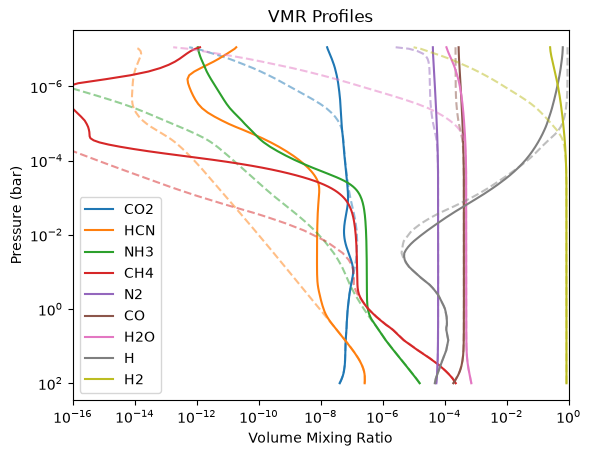

CPU times: user 76.3 ms, sys: 10.3 ms, total: 86.7 ms
Wall time: 85.5 ms


In [24]:
%%time
fig, ax = plt.subplots()
plot_vmr(
    result_photo_equil["vmr"][-1],
    result_photo_equil["pressure"],
    result_photo_equil["species"],
    initial_vmr=result_photo_equil["initial_vmr"],
    xlims=(1e-16, 1e0),
    ax=ax,
)
plt.show()


## Trying a loop over 10 planets

Here we sample a
small population of planets from given parameter ranges, solve each one twice, once with
weak eddy mixing, once with strong eddy mixing, and compare the resulting mixing ratios.

Sampled ranges (i change the minimum of planet mass to try to improve stability):

| Parameter  | Range          | Meaning                          |
|------------|----------------|-----------------------------------|
| `Teq_K`    | 300 – 3000 K   | Isothermal equilibrium temperature |
| `Rp_Rj`    | 0.1 – 2.0 Rjup | Planet radius                     |
| `Mp_Mj`    | 0.5 – 5.0 Mjup| Planet mass                       |


In [32]:
%%time
# Fixed seed 
rng = np.random.default_rng(42)

n_planets = 10
param_ranges = {
    "Teq_K": (300.0, 3000.0),
    "Rp_Rj": (0.1, 2.0),
    "Mp_Mj": (0.5, 5.0),
    "Rstar_Rs": (0.5, 2.0),
}

planets = {name: rng.uniform(lo, hi, size=n_planets) for name, (lo, hi) in param_ranges.items()}

for i in range(n_planets):
    print(
        f"Planet {i:2d}: Teq={planets['Teq_K'][i]:7.1f} K  "
        f"Rp={planets['Rp_Rj'][i]:.2f} Rjup  Mp={planets['Mp_Mj'][i]:.2f} Mjup  "
        f"Rstar={planets['Rstar_Rs'][i]:.2f} Rsun"
    )


Planet  0: Teq= 2389.7 K  Rp=0.80 Rjup  Mp=3.91 Mjup  Rstar=1.62 Rsun
Planet  1: Teq= 1485.0 K  Rp=1.86 Rjup  Mp=2.10 Mjup  Rstar=1.95 Rsun
Planet  2: Teq= 2618.2 K  Rp=1.32 Rjup  Mp=4.87 Mjup  Rstar=0.99 Rsun
Planet  3: Teq= 2182.9 K  Rp=1.66 Rjup  Mp=4.52 Mjup  Rstar=1.06 Rsun
Planet  4: Teq=  554.3 K  Rp=0.94 Rjup  Mp=4.00 Mjup  Rstar=1.20 Rsun
Planet  5: Teq= 2934.2 K  Rp=0.53 Rjup  Mp=1.38 Mjup  Rstar=0.78 Rsun
Planet  6: Teq= 2355.1 K  Rp=1.15 Rjup  Mp=2.60 Mjup  Rstar=0.69 Rsun
Planet  7: Teq= 2422.4 K  Rp=0.22 Rjup  Mp=0.70 Mjup  Rstar=1.21 Rsun
Planet  8: Teq=  645.9 K  Rp=1.67 Rjup  Mp=1.19 Mjup  Rstar=0.84 Rsun
Planet  9: Teq= 1516.0 K  Rp=1.30 Rjup  Mp=3.57 Mjup  Rstar=1.50 Rsun
CPU times: user 645 μs, sys: 246 μs, total: 891 μs
Wall time: 686 μs


For each planet we build an **isothermal** T(p) profile at its own `Teq`, reusing the
pressure grid already loaded. We reuse the reduced `network`, and start each solve from that planet's
own ACE-equilibrium composition.

Two constant $K_{zz}$ values:

- **Low**: $10^{5}\ \mathrm{cm^2/s}$ weak vertical mixing.
- **High**: $10^{11}\ \mathrm{cm^2/s}$ strong vertical mixing.

This cell runs `10 planets x 2 Kzz cases = 20` full solves


In [33]:
%%time
KZZ_LOW = 1e6 << u.cm**2 / u.s 
KZZ_HIGH = 1e11 << u.cm**2 / u.s

# One solver instance is reused for every planet/Kzz case: `set_system_parameters` recompiles
# the network for the new temperature/pressure/Kzz each time it's called, so there's no need to build a fresh Rosenbrock object per iteration.
diseq_solver = Rosenbrock(network=network)

survey_results = []  # one {"low": Solution, "high": Solution} dict per planet

for i in range(n_planets):
    teq = planets["Teq_K"][i] << u.K
    rp = planets["Rp_Rj"][i] << u.Rjup
    mp = planets["Mp_Mj"][i] << u.Mjup

    # Isothermal T(p)
    temperature_i = np.full(pressure.shape, teq.value) << u.K

    equil_vmr_i = equil_chemistry_ace(
        temperature=temperature_i,
        pressure=pressure,
        composition=network.species,
        elements=["H", "He", "C", "N", "O"],
        abundances=[12, 10.93, 8.39, 7.86, 8.73],
    )

    planet_result = {}
    for label, kzz_value in [("low", KZZ_LOW), ("high", KZZ_HIGH)]:
        # Kzz must be an array matching the pressure grid, even though it's a single value here.
        kzz_i = np.full(pressure.shape, kzz_value.value) << kzz_value.unit

        diseq_solver.set_system_parameters(
            temperature=temperature_i,
            pressure=pressure,
            kzz=kzz_i,
            planet_radius=rp,
            planet_mass=mp,
        )
        solution = diseq_solver.solve(
            vmr=equil_vmr_i,
            t_span=[0, 1e16],
            enable_diffusion=False,
            maxiter=1000,
        )
        planet_result[label] = solution
        print(f"  planet {i:2d} [{label:>4} Kzz] Teq={teq:6.0f}  success={solution['success']}")

    survey_results.append(planet_result)


  planet  0 [ low Kzz] Teq=  2390 K  success=True
  planet  0 [high Kzz] Teq=  2390 K  success=True
  planet  1 [ low Kzz] Teq=  1485 K  success=False
  planet  1 [high Kzz] Teq=  1485 K  success=True
  planet  2 [ low Kzz] Teq=  2618 K  success=True
  planet  2 [high Kzz] Teq=  2618 K  success=True
  planet  3 [ low Kzz] Teq=  2183 K  success=True
  planet  3 [high Kzz] Teq=  2183 K  success=True
  planet  4 [ low Kzz] Teq=   554 K  success=False
  planet  4 [high Kzz] Teq=   554 K  success=False
  planet  5 [ low Kzz] Teq=  2934 K  success=True
  planet  5 [high Kzz] Teq=  2934 K  success=True
  planet  6 [ low Kzz] Teq=  2355 K  success=True
  planet  6 [high Kzz] Teq=  2355 K  success=True
  planet  7 [ low Kzz] Teq=  2422 K  success=True
  planet  7 [high Kzz] Teq=  2422 K  success=True
  planet  8 [ low Kzz] Teq=   646 K  success=False
  planet  8 [high Kzz] Teq=   646 K  success=False
  planet  9 [ low Kzz] Teq=  1516 K  success=False
  planet  9 [high Kzz] Teq=  1516 K  success

Now compare, per planet, the actual VMR profiles between the low-$K_{zz}$ and
high-$K_{zz}$ runs for the five species that are usually the most quench-sensitive
(`CO`/`CH4` interconversion and `NH3` are classic disequilibrium-chemistry tracers). Each
subplot is one planet; each species gets its own color; **solid** lines are the
high-$K_{zz}$ (strongly mixed) case and **dashed** lines are the low-$K_{zz}$ (weakly mixed)
case — the same solid/dashed convention `plot_vmr` uses elsewhere in this notebook for
final-vs-initial VMR. Wherever a solid and dashed line of the same color diverge, that
species is being quenched by vertical mixing at that pressure:


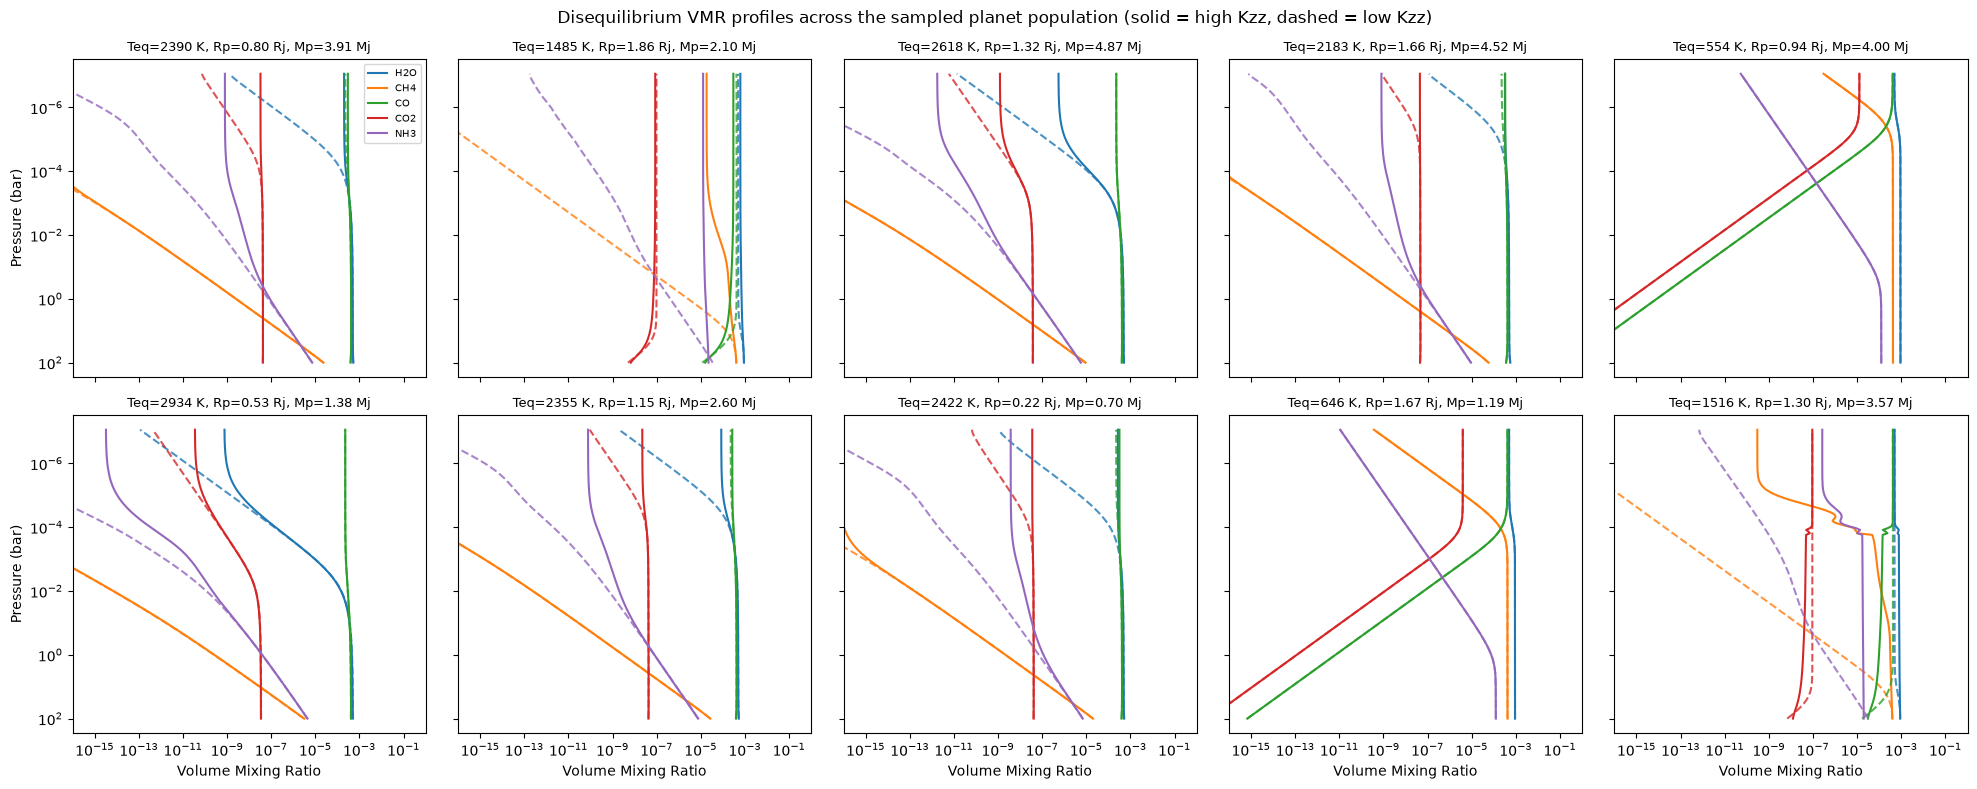

CPU times: user 391 ms, sys: 36.2 ms, total: 427 ms
Wall time: 425 ms


In [34]:
%%time
species_to_compare = ["H2O", "CH4", "CO", "CO2", "NH3"]
species_colors = dict(zip(species_to_compare, plt.cm.tab10.colors))

fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)

for i, ax in enumerate(axes.flat):
    vmr_low = survey_results[i]["low"]["vmr"][-1]
    vmr_high = survey_results[i]["high"]["vmr"][-1]
    p = survey_results[i]["low"]["pressure"].to(u.bar)

    for sp in species_to_compare:
        idx = network.species.index(sp)
        color = species_colors[sp]
        ax.plot(vmr_low[idx], p.value, "--", color=color, alpha=0.8)
        ax.plot(vmr_high[idx], p.value, "-", color=color, label=sp)

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-16, 1e0)
    ax.invert_yaxis()
    ax.set_title(
        f"Teq={planets['Teq_K'][i]:.0f} K, Rp={planets['Rp_Rj'][i]:.2f} Rj, Mp={planets['Mp_Mj'][i]:.2f} Mj",
        fontsize=9,
    )
    if i >= 5:
        ax.set_xlabel("Volume Mixing Ratio")
    if i % 5 == 0:
        ax.set_ylabel("Pressure (bar)")

axes.flat[0].legend(fontsize=7, loc="best")
fig.suptitle("Disequilibrium VMR profiles across the sampled planet population (solid = high Kzz, dashed = low Kzz)")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()
